# RAG-Powered Document Assistant: Raspberry Pi Product Docs

**Abdelrahman Hesham**

This notebook builds and evaluates the RAG pipeline behind the app. The documents are the official
Raspberry Pi product briefs (8 PDFs). The assistant answers questions about the products using only these
documents and cites the file and page each answer came from.

Pipeline: load PDFs → clean → chunk → embed with `nomic-embed-text` (Ollama) → store in Chroma →
retrieve with MMR → prompt `llama3.2` (Ollama) → answer with citations → evaluate → export the vector store
for the FastAPI backend.

Requirements: Ollama running locally with `ollama pull llama3.2` and `ollama pull nomic-embed-text`.

In [1]:
import json
import re
import shutil
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import pymupdf

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_ollama import OllamaEmbeddings, ChatOllama
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

pd.set_option("display.max_colwidth", 120)

In [2]:
ROOT = Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
VECTOR_DIR = ROOT / "backend" / "data" / "vector_store"

EMBEDDING_MODEL = "nomic-embed-text"
LLM_MODEL = "llama3.2"
COLLECTION_NAME = "raspberry_pi_docs"

CHUNK_SIZE = 800
CHUNK_OVERLAP = 120
TOP_K = 4
FETCH_K = 20
LAMBDA_MULT = 0.9

## 1. Domain & Data

Domain: **Raspberry Pi product documentation**. A support assistant for a store or makerspace that sells
Raspberry Pi boards needs to answer spec questions (CPU, RAM, ports, power, temperature, prices) correctly,
and these are exactly the kind of answers an LLM tends to mix up between similar boards.

The source list is in `data/sources.csv`. The PDFs are downloaded into `data/raw/` (not committed to GitHub).

In [3]:
sources = pd.read_csv(ROOT / "data" / "sources.csv")
RAW_DIR.mkdir(parents=True, exist_ok=True)

for _, row in sources.iterrows():
    path = RAW_DIR / row["file"]
    if not path.exists():
        r = requests.get(row["url"], headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        r.raise_for_status()
        path.write_bytes(r.content)

sources["size_kb"] = [round((RAW_DIR / f).stat().st_size / 1024) for f in sources["file"]]
sources[["file", "product", "size_kb"]]

,file,product,size_kb
0,raspberry-pi-5-product-brief.pdf,Raspberry Pi 5,830
1,raspberry-pi-4-product-brief.pdf,Raspberry Pi 4 Model B,20874
2,raspberry-pi-400-product-brief.pdf,Raspberry Pi 400,5225
3,raspberry-pi-zero-2-w-product-brief.pdf,Raspberry Pi Zero 2 W,1560
4,cm4-product-brief.pdf,Raspberry Pi Compute Module 4,756
5,pico-product-brief.pdf,Raspberry Pi Pico,616
6,pico-2-product-brief.pdf,Raspberry Pi Pico 2,823
7,camera-module-3-product-brief.pdf,Raspberry Pi Camera Module 3,1215


## 2.1 Load & Inspect

First I compared two PDF readers on the same pages, because spec values (dates, prices) are printed on
their own line next to the label in these briefs.

In [4]:
checks = [("raspberry-pi-4-product-brief.pdf", 2, "2034"),
          ("raspberry-pi-400-product-brief.pdf", 3, "$80"),
          ("raspberry-pi-5-product-brief.pdf", 2, "5V/5A")]

rows = []
for file, page, value in checks:
    pypdf_text = PyPDFLoader(str(RAW_DIR / file)).load()[page].page_content
    mupdf_text = pymupdf.open(RAW_DIR / file)[page].get_text()
    rows.append({"file": file, "page": page + 1, "value": value,
                 "found_by_pypdf": value in pypdf_text, "found_by_pymupdf": value in mupdf_text})
pd.DataFrame(rows)

,file,page,value,found_by_pypdf,found_by_pymupdf
0,raspberry-pi-4-product-brief.pdf,3,2034,True,True
1,raspberry-pi-400-product-brief.pdf,4,$80,True,True
2,raspberry-pi-5-product-brief.pdf,3,5V/5A,True,True


Both readers keep these values in the raw text. In my first version they were still missing from the chunks,
because my own cleaning step deleted every line without words, so `2034` and `$80` disappeared (see *Failure cases*).

PyMuPDF is used to load the documents because it can also detect tables (`find_tables`). Tables like the
Camera Module 3 *Variants* table come out as one cell per line, which a small LLM cannot map back to the right
column, so every row of a real table (3+ columns) is also written as one line (`row label - column: value; ...`)
and added to the page text. Two-column spec lists are skipped because they are already readable as label / value lines.

In [5]:
def table_rows(page):
    rows = []
    for table in page.find_tables().tables:
        data = table.extract()
        if len(data) < 2 or len(data[0]) < 3:
            continue
        header = [(h or "").replace("\n", " ").strip() for h in data[0]]
        for row in data[1:]:
            cells = [(c or "").replace("\n", " ").strip() for c in row]
            values = [f"{h}: {v}" for h, v in zip(header[1:], cells[1:]) if h and v]
            if cells[0] and values:
                rows.append(f"{cells[0]} - " + "; ".join(values))
    return rows


def load_pdf(path, file, product):
    docs = []
    for i, page in enumerate(pymupdf.open(path)):
        text = page.get_text()
        rows = table_rows(page)
        if rows:
            text += "\nTable rows:\n" + "\n".join(rows)
        docs.append(Document(page_content=text, metadata={"source": file, "product": product, "page": i}))
    return docs


pages = []
failed = []
for _, row in sources.iterrows():
    try:
        pages.extend(load_pdf(RAW_DIR / row["file"], row["file"], row["product"]))
    except Exception as e:
        failed.append((row["file"], str(e)))

print("documents:", len(sources) - len(failed))
print("pages:", len(pages))
print("failed to parse:", failed)

documents: 8
pages: 58
failed to parse: []


In [6]:
cm3 = [p for p in pages if p.metadata["source"] == "camera-module-3-product-brief.pdf"][4]
print(cm3.page_content[cm3.page_content.index("Table rows"):][:900])

Table rows:
Focus range - Camera Module 3: 10cm–∞; Camera Module 3 NoIR: 10cm–∞; Camera Module 3 Wide: 5cm–∞; Camera Module 3 Wide NoIR: 5cm–∞
Focal length - Camera Module 3: 4.74mm; Camera Module 3 NoIR: 4.74mm; Camera Module 3 Wide: 2.75mm; Camera Module 3 Wide NoIR: 2.75mm
Diagonal field of view - Camera Module 3: 75 degrees; Camera Module 3 NoIR: 75 degrees; Camera Module 3 Wide: 120 degrees; Camera Module 3 Wide NoIR: 120 degrees
Horizontal field of view - Camera Module 3: 66 degrees; Camera Module 3 NoIR: 66 degrees; Camera Module 3 Wide: 102 degrees; Camera Module 3 Wide NoIR: 102 degrees
Vertical field of view - Camera Module 3: 41 degrees; Camera Module 3 NoIR: 41 degrees; Camera Module 3 Wide: 67 degrees; Camera Module 3 Wide NoIR: 67 degrees
Focal ratio (F-stop) - Camera Module 3: F1.8; Camera Module 3 NoIR: F1.8; Camera Module 3 Wide: F2.2; Camera Module 3 Wide NoIR: F2.2
Inf


In [7]:
page_stats = pd.DataFrame([{"file": p.metadata["source"], "page": p.metadata["page"] + 1,
                            "chars": len(p.page_content)} for p in pages])

summary = page_stats.groupby("file").agg(pages=("page", "count"),
                                         total_chars=("chars", "sum"),
                                         min_chars=("chars", "min"))
summary

,pages,total_chars,min_chars
file,,,
camera-module-3-product-brief.pdf,7,6493,48
cm4-product-brief.pdf,8,8986,0
pico-2-product-brief.pdf,6,4639,48
pico-product-brief.pdf,6,3910,21
raspberry-pi-4-product-brief.pdf,7,4518,0
raspberry-pi-400-product-brief.pdf,11,7085,39
raspberry-pi-5-product-brief.pdf,7,4313,0
raspberry-pi-zero-2-w-product-brief.pdf,6,4288,43


In [8]:
print("pages with less than 100 characters (image-only / need OCR?):")
page_stats[page_stats["chars"] < 100]

pages with less than 100 characters (image-only / need OCR?):


,file,page,chars
3,raspberry-pi-5-product-brief.pdf,4,63
5,raspberry-pi-5-product-brief.pdf,6,0
6,raspberry-pi-5-product-brief.pdf,7,78
10,raspberry-pi-4-product-brief.pdf,4,71
12,raspberry-pi-4-product-brief.pdf,6,0
13,raspberry-pi-4-product-brief.pdf,7,78
18,raspberry-pi-400-product-brief.pdf,5,70
19,raspberry-pi-400-product-brief.pdf,6,47
20,raspberry-pi-400-product-brief.pdf,7,47
21,raspberry-pi-400-product-brief.pdf,8,47


In [9]:
sample = [p for p in pages if p.metadata["source"] == "raspberry-pi-400-product-brief.pdf"][4]
print(sample.page_content[:700])

5
UK
US
DE
Keyboard print layouts
Raspberry Pi 400 – Raspberry Pi Ltd



**Inspection notes**

- **Documents / pages:** 8 PDF files, 58 pages in total. All files are PDF, and all 8 were parsed without errors.
- **OCR:** none needed. The briefs are born-digital PDFs with a real text layer. The 24 pages with less than
  100 characters are not scanned pages: they are cover and back pages, dimension drawings and the Raspberry Pi 400
  keyboard layout pages, where the content is vector graphics. They carry no useful text and are removed by the
  cleaning step below.
- **Messy parts to clean:** numbers from the dimension drawings, key labels from the keyboard layouts, control
  characters (`\x07`) and tabs from the PDF layout, cover pages with only the product name, and tables that come
  out one cell per line.

### Cleaning

The extracted text has some noise that does not help retrieval:
- long runs of numbers from the dimension drawings,
- keyboard layout pages in the Raspberry Pi 400 brief (single keys, one per line),
- extra spaces inside lines,
- cover and back pages that only contain the product name.

Rules: a short run (1–3 lines) of lines without words is a value like `2034` or `$35`, so it is joined to the
line before it ("...until at least January 2034"). A longer run is drawing or keyboard noise and is removed.
Pages with less than 150 characters after cleaning are dropped.

In [10]:
MIN_PAGE_CHARS = 150


def has_words(line):
    return re.search(r"[A-Za-z]{2,}", line) is not None


def clean_text(text):
    text = text.replace("\x07", "").replace("\t", " ")
    lines = [" ".join(l.split()) for l in text.split("\n")]
    lines = [l for l in lines if l]
    cleaned = []
    i = 0
    while i < len(lines):
        if has_words(lines[i]):
            cleaned.append(lines[i])
            i += 1
            continue
        j = i
        while j < len(lines) and not has_words(lines[j]):
            j += 1
        run = lines[i:j]
        if len(run) <= 3 and cleaned:
            cleaned[-1] = cleaned[-1] + " " + " ".join(run)
        i = j
    return "\n".join(cleaned)


clean_pages = []
for p in pages:
    text = clean_text(p.page_content)
    if len(text) >= MIN_PAGE_CHARS:
        clean_pages.append(Document(page_content=text, metadata=p.metadata))

before = sum(len(p.page_content) for p in pages)
after = sum(len(p.page_content) for p in clean_pages)
print(f"pages kept: {len(clean_pages)} of {len(pages)}")
print(f"characters: {before} -> {after} ({100 * (before - after) / before:.1f}% removed)")

pages kept: 31 of 58
characters: 44232 -> 41577 (6.0% removed)


In [11]:
print(clean_text(sample.page_content)[:700] or "(page removed: only keyboard layout / drawing text)")
print("-----")
pi4_spec = [p for p in clean_pages if p.metadata["source"] == "raspberry-pi-4-product-brief.pdf"][1]
print(pi4_spec.page_content[-500:])

UK
US
DE
Keyboard print layouts
Raspberry Pi 400 – Raspberry Pi Ltd
-----
es separate PoE HAT)
Operating temperature
0ºC to 50ºC
MTBF2 Ground Benign
211 000 hours
Production lifetime
Raspberry Pi 4 Model B will remain in production until at least January 2034
Compliance
For a full list of local and regional product approvals, please visit
pip.raspberrypi.com
List price
1GB $35
2GB $67.50
3GB $83.75
4GB $100
8GB $165
1 A good-quality 2.5A power supply can be used if downstream USB peripherals consume less than 500mA in total.
2 Mean Time Between Failure
Specification 2


## 2.2 Chunking Strategy

In [12]:
rows = []
for size in [400, 800, 1200]:
    splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=int(size * 0.15))
    parts = splitter.split_documents(clean_pages)
    rows.append({"chunk_size": size, "overlap": int(size * 0.15), "chunks": len(parts),
                 "avg_chars": int(np.mean([len(c.page_content) for c in parts]))})
pd.DataFrame(rows)

,chunk_size,overlap,chunks,avg_chars
0,400,60,132,329
1,800,120,75,606
2,1200,180,55,816


In [13]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " ", ""],
)
raw_chunks = splitter.split_documents(clean_pages)

chunks = []
for i, c in enumerate(raw_chunks):
    text = f"Product: {c.metadata['product']}\n{c.page_content}"
    chunks.append(Document(page_content=text, metadata={**c.metadata, "chunk_id": i}))

print("chunks:", len(chunks))
print(chunks[3].page_content)

chunks: 75
Product: Raspberry Pi 5
Raspberry Pi 5
Specification
Processor
Broadcom BCM2712 2.4GHz quad-core 64-bit Arm Cortex-A76 CPU,
with Cryptographic Extension, 512KB per-core L2 caches, and a 2MB
shared L3 cache
Features
VideoCore VII GPU, supporting OpenGL ES 3.1, Vulkan 1.2
Dual 4Kp60 HDMI® display output with HDR support
4Kp60 HEVC decoder
LPDDR4X-4267 SDRAM (options for 1GB, 2GB, 4GB, 8GB and 16GB)
Dual-band 802.11ac Wi-Fi®
Bluetooth 5.0 / Bluetooth Low Energy (BLE)
microSD card slot, with support for high-speed SDR104 mode
2 × USB 3.0 ports, supporting simultaneous 5Gbps operation
2 × USB 2.0 ports
Gigabit Ethernet, with PoE+ support (requires separate PoE+ HAT)
2 × 4-lane MIPI camera / display transceivers
PCIe 2.0 x1 interface for fast peripherals (requires separate M.2 HAT or
other adapter)


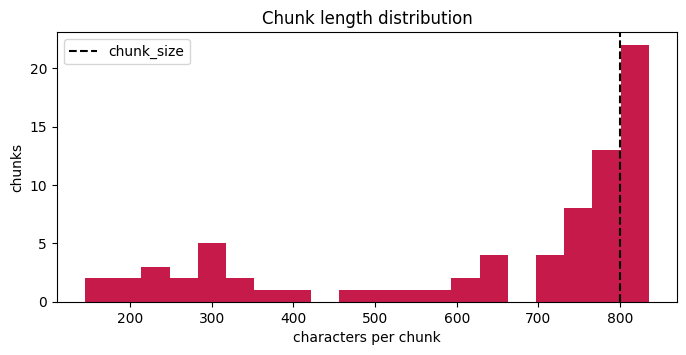

,chunks per file
cm4-product-brief.pdf,15
raspberry-pi-400-product-brief.pdf,13
camera-module-3-product-brief.pdf,11
raspberry-pi-zero-2-w-product-brief.pdf,8
pico-2-product-brief.pdf,8
raspberry-pi-4-product-brief.pdf,7
raspberry-pi-5-product-brief.pdf,7
pico-product-brief.pdf,6


In [14]:
lengths = [len(c.page_content) for c in chunks]
plt.figure(figsize=(8, 3.5))
plt.hist(lengths, bins=20, color="#c51a4a")
plt.axvline(CHUNK_SIZE, color="black", linestyle="--", label="chunk_size")
plt.xlabel("characters per chunk")
plt.ylabel("chunks")
plt.legend()
plt.title("Chunk length distribution")
plt.show()

pd.Series([c.metadata["source"] for c in chunks]).value_counts().rename("chunks per file")

**Why chunk_size = 800 and overlap = 120 (15%)?**

- Product briefs are short pages where one spec section (for example *Specification* or *Variants*) is
  roughly 500–900 characters (average chunk with 800 is about 600 characters, 75 chunks in total). 800 characters keeps a full spec block in one chunk, so a question like
  "what RAM options..." finds the whole list instead of half of it.
- 400 gives many tiny chunks that cut tables in the middle; 1200 mixes several unrelated sections in
  one chunk, which makes the context noisy for a small 3B model.
- 120 characters of overlap (about two spec lines) keeps rows that fall on a boundary in both chunks.
- `RecursiveCharacterTextSplitter` splits on paragraphs, then lines, then sentences, so it does not cut
  in the middle of a spec row like a plain fixed-size splitter would.
- Every chunk starts with `Product: <name>`. Many spec lines ("Operating temperature: 0°C to 50°C") look the
  same in every brief, so a chunk without the name does not say which board it is about. In section 2.6 the
  file hit rate is the same with and without the prefix on these questions, so the prefix mainly helps the LLM:
  every context block says which product its spec lines belong to.

## 2.3 Embeddings & Vector Store

In [15]:
embedding = OllamaEmbeddings(model=EMBEDDING_MODEL)

v1 = embedding.embed_query("Raspberry Pi 5 memory options")
v2 = embedding.embed_query("How much RAM does the Pi 5 have?")
v3 = embedding.embed_query("Camera Module 3 field of view")


def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))


print("embedding size:", len(v1))
print("similar questions:", round(cosine(v1, v2), 3))
print("different topics:", round(cosine(v1, v3), 3))

embedding size: 768
similar questions: 0.773
different topics: 0.381


In [16]:
if VECTOR_DIR.exists():
    shutil.rmtree(VECTOR_DIR)

start = time.time()
vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embedding,
    ids=[f"chunk-{c.metadata['chunk_id']}" for c in chunks],
    collection_name=COLLECTION_NAME,
    persist_directory=str(VECTOR_DIR),
    collection_metadata={"hnsw:space": "cosine"},
)
print(f"stored {vectorstore._collection.count()} chunks in {time.time() - start:.1f}s")

stored 75 chunks in 72.9s


In [17]:
del vectorstore
vectorstore = Chroma(persist_directory=str(VECTOR_DIR), embedding_function=embedding,
                     collection_name=COLLECTION_NAME)
print("reloaded from disk:", vectorstore._collection.count(), "chunks")

reloaded from disk: 75 chunks


## 2.4 Retrieval & Prompting

In [18]:
def retrieve(question, k=TOP_K):
    return vectorstore.max_marginal_relevance_search(question, k=k, fetch_k=FETCH_K, lambda_mult=LAMBDA_MULT)


def source_name(doc):
    return f"{doc.metadata['source']} (page {doc.metadata['page'] + 1})"


for doc in retrieve("What RAM options are available for the Raspberry Pi 4 Model B?"):
    print(source_name(doc))
    print(doc.page_content[:200].replace("\n", " | "), "\n")

raspberry-pi-4-product-brief.pdf (page 2)
Product: Raspberry Pi 4 Model B | Raspberry Pi 4 Model B | Overview | Raspberry Pi 4 Model B features a high-performance 64-bit quad-core processor, dual-display support | at resolutions up to 4K via a pair o 

raspberry-pi-4-product-brief.pdf (page 3)
Product: Raspberry Pi 4 Model B | Raspberry Pi 4 Model B | Specification | Processor | Broadcom BCM2711, quad-core Cortex-A72 (Arm v8) 64-bit SoC @ | 1.8GHz | Memory | 1GB, 2GB, 3GB, 4GB or 8GB LPDDR4 (depending on 

raspberry-pi-4-product-brief.pdf (page 3)
Product: Raspberry Pi 4 Model B | microSD card slot for loading operating system and data storage | Input power | 5V DC via USB-C connector (minimum 3A1) | 5V DC via GPIO header (minimum 3A1) | Power over Ether 

cm4-product-brief.pdf (page 2)
Product: Raspberry Pi Compute Module 4 | Raspberry Pi Compute Module 4 | Overview | Raspberry Pi Compute Module 4 harnesses the compute power of Raspberry Pi 4 Model B, bringing it to | a smaller form f

In [19]:
eval_set = [
    {"question": "What CPU does the Raspberry Pi 5 use and how fast is it?",
     "expected_source": "raspberry-pi-5-product-brief.pdf", "keywords": ["Cortex-A76", "2.4"]},
    {"question": "What RAM options are available for the Raspberry Pi 4 Model B?",
     "expected_source": "raspberry-pi-4-product-brief.pdf", "keywords": ["1GB", "8GB"]},
    {"question": "What is the operating temperature range of the Raspberry Pi Zero 2 W?",
     "expected_source": "raspberry-pi-zero-2-w-product-brief.pdf", "keywords": ["-20", "70"]},
    {"question": "How many GPIO pins does the Raspberry Pi Pico have, and how many are analogue inputs?",
     "expected_source": "pico-product-brief.pdf", "keywords": ["26", "3"]},
    {"question": "Which image sensor is used in the Camera Module 3?",
     "expected_source": "camera-module-3-product-brief.pdf", "keywords": ["IMX708"]},
    {"question": "What is the diagonal field of view of the Camera Module 3 Wide?",
     "expected_source": "camera-module-3-product-brief.pdf", "keywords": ["120"]},
    {"question": "How much does the Raspberry Pi 400 kit cost?",
     "expected_source": "raspberry-pi-400-product-brief.pdf", "keywords": ["80"]},
    {"question": "What power input does the Raspberry Pi 5 need?",
     "expected_source": "raspberry-pi-5-product-brief.pdf", "keywords": ["5V", "5A"]},
    {"question": "Until when will the Raspberry Pi 4 Model B stay in production?",
     "expected_source": "raspberry-pi-4-product-brief.pdf", "keywords": ["2034"]},
    {"question": "What wireless connectivity does the Pico 2 W offer?",
     "expected_source": "pico-2-product-brief.pdf", "keywords": ["Bluetooth", "5.2"]},
    {"question": "What is the operating temperature range of the Compute Module 4?",
     "expected_source": "cm4-product-brief.pdf", "keywords": ["-20", "85"]},
    {"question": "Does the Raspberry Pi 5 have a real-time clock?",
     "expected_source": "raspberry-pi-5-product-brief.pdf", "keywords": ["RTC|real-time clock"]},
    {"question": "What is the battery life of the iPhone 15?",
     "expected_source": None, "keywords": []},
    {"question": "How do I install Windows 11 on a gaming laptop?",
     "expected_source": None, "keywords": []},
]

retrieval_rows = []
for item in eval_set:
    docs = retrieve(item["question"])
    found = [d.metadata["source"] for d in docs]
    retrieval_rows.append({
        "question": item["question"],
        "top_source": source_name(docs[0]),
        "expected_in_top_k": None if item["expected_source"] is None else item["expected_source"] in found,
    })

pd.DataFrame(retrieval_rows)

,question,top_source,expected_in_top_k
0,What CPU does the Raspberry Pi 5 use and how fast is it?,raspberry-pi-5-product-brief.pdf (page 2),True
1,What RAM options are available for the Raspberry Pi 4 Model B?,raspberry-pi-4-product-brief.pdf (page 2),True
2,What is the operating temperature range of the Raspberry Pi Zero 2 W?,raspberry-pi-zero-2-w-product-brief.pdf (page 4),True
3,"How many GPIO pins does the Raspberry Pi Pico have, and how many are analogue inputs?",pico-product-brief.pdf (page 2),True
4,Which image sensor is used in the Camera Module 3?,camera-module-3-product-brief.pdf (page 2),True
5,What is the diagonal field of view of the Camera Module 3 Wide?,camera-module-3-product-brief.pdf (page 5),True
6,How much does the Raspberry Pi 400 kit cost?,raspberry-pi-400-product-brief.pdf (page 4),True
7,What power input does the Raspberry Pi 5 need?,raspberry-pi-5-product-brief.pdf (page 2),True
8,Until when will the Raspberry Pi 4 Model B stay in production?,raspberry-pi-4-product-brief.pdf (page 3),True
9,What wireless connectivity does the Pico 2 W offer?,pico-2-product-brief.pdf (page 2),True


### Prompt template

Retrieved chunks from the same page are merged into one numbered block, so every source appears once.
The prompt tells the model to use only the numbered context blocks, to cite them as `[1]`, `[2]`,
and to give a fixed "not found" sentence when the answer is not in the context.

In [20]:
NOT_FOUND = "I could not find the answer in the documents."

TEMPLATE = """You are a helpful assistant that answers questions about Raspberry Pi products.
Use only the context below to answer. Do not use any outside knowledge.
If the context does not contain the answer, reply exactly: "I could not find the answer in the documents."
Copy numbers and units exactly as they are written in the context.
Keep the answer short and cite the context numbers you used, like [1] or [2].

Context:
{context}

Question: {question}

Answer:"""

prompt = PromptTemplate.from_template(TEMPLATE)
llm = ChatOllama(model=LLM_MODEL, temperature=0, num_predict=300, seed=365)
rag_chain = prompt | llm | StrOutputParser()


def group_by_page(docs):
    groups = {}
    for d in docs:
        key = source_name(d)
        body = d.page_content.split("\n", 1)[1] if d.page_content.startswith("Product:") else d.page_content
        if key not in groups:
            groups[key] = {"product": d.metadata["product"], "texts": []}
        groups[key]["texts"].append(body)
    return groups


def format_context(docs):
    blocks = []
    for i, (name, g) in enumerate(group_by_page(docs).items(), start=1):
        blocks.append(f"[{i}] {name} - {g['product']}\n" + "\n".join(g["texts"]))
    return "\n\n".join(blocks)


docs = retrieve("What CPU does the Raspberry Pi 5 use?")
print(prompt.format(context=format_context(docs), question="What CPU does the Raspberry Pi 5 use?")[:1500])

You are a helpful assistant that answers questions about Raspberry Pi products.
Use only the context below to answer. Do not use any outside knowledge.
If the context does not contain the answer, reply exactly: "I could not find the answer in the documents."
Copy numbers and units exactly as they are written in the context.
Keep the answer short and cite the context numbers you used, like [1] or [2].

Context:
[1] raspberry-pi-5-product-brief.pdf (page 2) - Raspberry Pi 5
Raspberry Pi 5
Overview
Welcome to the latest generation of Raspberry Pi: the everything computer.
Featuring a 64-bit quad-core Arm Cortex-A76 processor running at 2.4GHz, Raspberry Pi 5 delivers a
2 to 3× increase in CPU performance relative to Raspberry Pi 4. Alongside a substantial uplift in graphics
performance from an 800MHz VideoCore VII GPU; dual 4Kp60 display output over HDMI®; and state-of-
the-art camera support from a rearchitected Raspberry Pi Image Signal Processor, it provides a smooth
desktop experience

In [21]:
def best_distance(question):
    return vectorstore.similarity_search_with_score(question, k=1)[0][1]


def ask(question, use_guard=True, max_distance=None):
    if use_guard and best_distance(question) > max_distance:
        return {"answer": NOT_FOUND, "sources": [], "docs": []}
    docs = retrieve(question)
    answer = rag_chain.invoke({"context": format_context(docs), "question": question}).strip()
    return {"answer": answer, "sources": list(group_by_page(docs).keys()), "docs": docs}


result = ask("What CPU does the Raspberry Pi 5 use?", use_guard=False)
print(result["answer"])
print()
for i, s in enumerate(result["sources"], start=1):
    print(f"[{i}] {s}")

The Raspberry Pi 5 uses a Broadcom BCM2712 2.4GHz quad-core 64-bit Arm Cortex-A76 CPU. [1]

[1] raspberry-pi-5-product-brief.pdf (page 2)
[2] raspberry-pi-5-product-brief.pdf (page 3)


## 2.5 Vision Component

Not included: this project follows the **Core Track** (text-only RAG).

## 2.6 Evaluation

In [22]:
def normalize(text):
    return text.replace("−", "-").replace("–", "-").replace(" ", "").lower()


def is_correct(answer, item):
    if item["expected_source"] is None:
        return "could not find" in answer.lower()
    answer_n = normalize(answer)
    return all(any(normalize(opt) in answer_n for opt in kw.split("|")) for kw in item["keywords"])

### Retrieval: does the product name in the chunk help?

Before generating answers, I compared retrieval hit rate (expected file inside the top 4 chunks) for the
10+ answerable questions with and without the `Product: <name>` prefix, using plain similarity search and MMR.

In [23]:
answerable = [e for e in eval_set if e["expected_source"]]

plain_store = Chroma.from_documents(
    documents=[Document(page_content=c.page_content, metadata=c.metadata) for c in raw_chunks],
    embedding=embedding, collection_name="no_prefix_test",
    collection_metadata={"hnsw:space": "cosine"},
)


def hit_rate(store, mmr):
    hits = 0
    for e in answerable:
        if mmr:
            docs = store.max_marginal_relevance_search(e["question"], k=TOP_K, fetch_k=FETCH_K, lambda_mult=LAMBDA_MULT)
        else:
            docs = store.similarity_search(e["question"], k=TOP_K)
        hits += e["expected_source"] in [d.metadata["source"] for d in docs]
    return hits / len(answerable)


comparison = pd.DataFrame({
    "similarity": [hit_rate(plain_store, False), hit_rate(vectorstore, False)],
    "mmr": [hit_rate(plain_store, True), hit_rate(vectorstore, True)],
}, index=["without product name", "with product name"])
plain_store.delete_collection()
comparison

,similarity,mmr
without product name,1.0,1.0
with product name,1.0,1.0


### Retrieval: which search settings?

Hit rate only checks the file. A stricter check is whether the retrieved chunks actually contain the
expected answer (for example the Zero 2 W spec chunk and not its safety page that also says "temperatures").

In [24]:
search_configs = {
    "similarity k=4": lambda q: vectorstore.similarity_search(q, k=4),
    "mmr k=4 lambda=0.7": lambda q: vectorstore.max_marginal_relevance_search(q, k=4, fetch_k=FETCH_K, lambda_mult=0.7),
    "mmr k=4 lambda=0.9": lambda q: vectorstore.max_marginal_relevance_search(q, k=4, fetch_k=FETCH_K, lambda_mult=0.9),
}

rows = []
for name, search in search_configs.items():
    missed = [e["question"] for e in answerable
              if not is_correct(" ".join(d.page_content for d in search(e["question"])), e)]
    rows.append({"search": name, "answer_in_context": f"{len(answerable) - len(missed)}/{len(answerable)}",
                 "missed": missed})
pd.DataFrame(rows)

,search,answer_in_context,missed
0,similarity k=4,11/12,[What is the diagonal field of view of the Camera Module 3 Wide?]
1,mmr k=4 lambda=0.7,11/12,[What is the operating temperature range of the Raspberry Pi Zero 2 W?]
2,mmr k=4 lambda=0.9,11/12,[What is the diagonal field of view of the Camera Module 3 Wide?]


All three settings find the answer for 11 of 12 questions, but they miss different ones:

- **MMR λ=0.7** drops the Zero 2 W spec chunk for safety-text chunks ("normal ambient temperatures") because they
  look "diverse". In an earlier run this gave a wrong answer (0–50 °C, the Raspberry Pi 400 values).
- **Similarity and MMR λ=0.9** miss the Camera Module 3 table-row line but still return the *Variants* page.

I use **MMR with λ=0.9** (`LAMBDA_MULT = 0.9`): it keeps MMR's de-duplication of near-identical chunks while
giving most of the weight to relevance.

### Out-of-scope guard

A small model sometimes answers from its own knowledge when the context is unrelated. I checked the cosine
distance of the closest chunk for answerable and out-of-scope questions to choose a threshold: if the
closest chunk is too far, the app answers "not found" without calling the LLM.

In [25]:
dist = pd.DataFrame([{"question": e["question"], "in_scope": e["expected_source"] is not None,
                      "best_distance": round(best_distance(e["question"]), 3)} for e in eval_set])
dist.sort_values("best_distance")

,question,in_scope,best_distance
6,How much does the Raspberry Pi 400 kit cost?,True,0.195
0,What CPU does the Raspberry Pi 5 use and how fast is it?,True,0.211
8,Until when will the Raspberry Pi 4 Model B stay in production?,True,0.211
4,Which image sensor is used in the Camera Module 3?,True,0.218
1,What RAM options are available for the Raspberry Pi 4 Model B?,True,0.218
2,What is the operating temperature range of the Raspberry Pi Zero 2 W?,True,0.220
3,"How many GPIO pins does the Raspberry Pi Pico have, and how many are analogue inputs?",True,0.221
10,What is the operating temperature range of the Compute Module 4?,True,0.226
9,What wireless connectivity does the Pico 2 W offer?,True,0.246
5,What is the diagonal field of view of the Camera Module 3 Wide?,True,0.275


In [26]:
in_max = dist[dist["in_scope"]]["best_distance"].max()
out_min = dist[~dist["in_scope"]]["best_distance"].min()
MAX_DISTANCE = round((in_max + out_min) / 2, 2)
print("max distance (in scope):", in_max)
print("min distance (out of scope):", out_min)
print("threshold:", MAX_DISTANCE)

max distance (in scope): 0.299
min distance (out of scope): 0.464
threshold: 0.38


### Answer quality on the test questions

In [27]:
rows = []
start = time.time()
for item in eval_set:
    t0 = time.time()
    res = ask(item["question"], use_guard=True, max_distance=MAX_DISTANCE)
    found = [d.metadata["source"] for d in res["docs"]]
    if item["expected_source"] is None:
        retrieval_ok = len(found) == 0
    else:
        retrieval_ok = item["expected_source"] in found
    correct = is_correct(res["answer"], item)
    rows.append({
        "question": item["question"],
        "retrieved_source": res["sources"][0] if res["sources"] else "-",
        "answer": res["answer"],
        "relevant_context": retrieval_ok,
        "correct": correct,
        "grounded": "grounded" if correct and retrieval_ok else "check",
        "seconds": round(time.time() - t0, 1),
    })

results = pd.DataFrame(rows)
print(f"total time: {time.time() - start:.0f}s")
results[["question", "retrieved_source", "answer", "relevant_context", "correct", "grounded"]]

total time: 1002s


,question,retrieved_source,answer,relevant_context,correct,grounded
0,What CPU does the Raspberry Pi 5 use and how fast is it?,raspberry-pi-5-product-brief.pdf (page 2),The Raspberry Pi 5 uses a 64-bit quad-core Arm Cortex-A76 processor running at 2.4GHz. [1],True,True,grounded
1,What RAM options are available for the Raspberry Pi 4 Model B?,raspberry-pi-4-product-brief.pdf (page 2),"The RAM options available for the Raspberry Pi 4 Model B are 1GB, 2GB, 3GB, 4GB, and 8GB LPDDR4, depending on the mo...",True,True,grounded
2,What is the operating temperature range of the Raspberry Pi Zero 2 W?,raspberry-pi-zero-2-w-product-brief.pdf (page 4),"The operating temperature range of the Raspberry Pi Zero 2 W is -20°C to +70°C. [1], [3]",True,True,grounded
3,"How many GPIO pins does the Raspberry Pi Pico have, and how many are analogue inputs?",pico-product-brief.pdf (page 2),"The Raspberry Pi Pico has 26 GPIO pins, and 3 of them can function as analogue inputs. [1] [2]",True,True,grounded
4,Which image sensor is used in the Camera Module 3?,camera-module-3-product-brief.pdf (page 2),The Sony IMX708 12-megapixel image sensor is used in the Camera Module 3. [1],True,True,grounded
5,What is the diagonal field of view of the Camera Module 3 Wide?,camera-module-3-product-brief.pdf (page 5),The diagonal field of view of the Camera Module 3 Wide is 102 degrees. [1],True,False,check
6,How much does the Raspberry Pi 400 kit cost?,raspberry-pi-400-product-brief.pdf (page 4),The Raspberry Pi 400 UK Kit costs $80. [1],True,True,grounded
7,What power input does the Raspberry Pi 5 need?,raspberry-pi-5-product-brief.pdf (page 2),"The Raspberry Pi 5 requires 5V/5A DC power via USB-C, with Power Delivery support. [2]",True,True,grounded
8,Until when will the Raspberry Pi 4 Model B stay in production?,raspberry-pi-4-product-brief.pdf (page 3),The Raspberry Pi 4 Model B will remain in production until at least January 2034 [1].,True,True,grounded
9,What wireless connectivity does the Pico 2 W offer?,pico-2-product-brief.pdf (page 2),The Raspberry Pi Pico 2 W offers 2.4GHz 802.11n wireless LAN and Bluetooth 5.2. [1],True,True,grounded


relevant context: 100%
correct answers:  93%
avg time per question: 71.5s


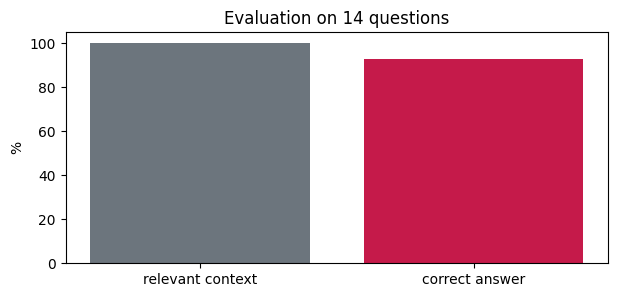

In [28]:
print(f"relevant context: {results['relevant_context'].mean():.0%}")
print(f"correct answers:  {results['correct'].mean():.0%}")
print(f"avg time per question: {results['seconds'].mean():.1f}s")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(["relevant context", "correct answer"],
       [results["relevant_context"].mean() * 100, results["correct"].mean() * 100],
       color=["#6c757d", "#c51a4a"])
ax.set_ylim(0, 105)
ax.set_ylabel("%")
ax.set_title(f"Evaluation on {len(results)} questions")
plt.show()

In [29]:
for _, r in results[~results["correct"]].iterrows():
    print("Q:", r["question"])
    print("A:", r["answer"])
    print("source:", r["retrieved_source"], "\n")

Q: What is the diagonal field of view of the Camera Module 3 Wide?
A: The diagonal field of view of the Camera Module 3 Wide is 102 degrees. [1]
source: camera-module-3-product-brief.pdf (page 5) 



### Failure cases and mitigations

Final result: relevant context for 14/14 questions and **13/14 correct answers** (12 answerable + 2 out of scope).
I ran the evaluation several times while building the pipeline. These are the failures I saw and what fixed them:

1. **Values deleted by my cleaning (first version).** The first cleaning removed every line without a word. In
   these briefs values like `2034`, `$80` or `$35` sit alone on their own line, so the context said "will remain in
   production until at least January" and the model answered **2030** (taken from another board) — a
   hallucination. *Fix:* short runs of value-only lines are joined to the line above; only long runs (drawings)
   are removed. The answer is now January 2034.
2. **Tables read one cell per line.** The model said the Camera Module 3 field of view was not in the documents
   and that the Raspberry Pi 400 kit costs $60 (the unit price). *Fix:* PyMuPDF `find_tables` + one text line per
   table row. The 400 kit answer is now $80.
3. **MMR picked "diverse" but useless chunks (λ=0.7).** For the Zero 2 W temperature question the context was
   safety text plus the Pi 400 spec, and the model answered 0–50 °C. *Fix:* λ=0.9, now -20 °C to +70 °C.
4. **Out-of-scope questions.** The retriever always returns something, and a small model may answer from its
   own knowledge. *Fix:* a distance threshold (0.38, between the farthest in-scope question 0.299 and the closest
   out-of-scope question 0.464) answers "not found" without calling the LLM. Both out-of-scope questions are rejected.
5. **Numbers lost in paraphrase.** The Raspberry Pi 5 power answer dropped "5A". *Fix:* the prompt asks to copy
   numbers and units exactly. The answer is now "5V/5A DC power via USB-C".
6. **Remaining failure.** Camera Module 3 Wide diagonal field of view: the right page is retrieved, but the 3B
   model reads the wrong table row (102°, the horizontal value, instead of 120°). Possible next steps: a larger
   model (for example `llama3.1:8b`), or one chunk per table row so only the matching row reaches the prompt.

Speed: about 70 s per question on a CPU-only machine (the notebook was run on a Colab CPU runtime); with a GPU
answers take a few seconds.

## 2.7 Export

In [30]:
config = {
    "collection_name": COLLECTION_NAME,
    "embedding_model": EMBEDDING_MODEL,
    "llm_model": LLM_MODEL,
    "chunk_size": CHUNK_SIZE,
    "chunk_overlap": CHUNK_OVERLAP,
    "top_k": TOP_K,
    "fetch_k": FETCH_K,
    "lambda_mult": LAMBDA_MULT,
    "max_distance": MAX_DISTANCE,
    "num_documents": len(sources),
    "num_chunks": len(chunks),
    "created_at": datetime.now().isoformat(timespec="seconds"),
}
(VECTOR_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

size_mb = sum(f.stat().st_size for f in VECTOR_DIR.rglob("*") if f.is_file()) / 1024 / 1024
print(json.dumps(config, indent=2))
print(f"vector store size: {size_mb:.2f} MB")
for f in sorted(VECTOR_DIR.rglob("*")):
    print(" ", f.relative_to(VECTOR_DIR))

{
  "collection_name": "raspberry_pi_docs",
  "embedding_model": "nomic-embed-text",
  "llm_model": "llama3.2",
  "chunk_size": 800,
  "chunk_overlap": 120,
  "top_k": 4,
  "fetch_k": 20,
  "lambda_mult": 0.9,
  "max_distance": 0.38,
  "num_documents": 8,
  "num_chunks": 75,
  "created_at": "2026-11-26T16:32:25"
}
vector store size: 1.31 MB
  70b19938-3773-4760-b2ca-53aa80b3c27f
  70b19938-3773-4760-b2ca-53aa80b3c27f/data_level0.bin
  70b19938-3773-4760-b2ca-53aa80b3c27f/header.bin
  70b19938-3773-4760-b2ca-53aa80b3c27f/length.bin
  70b19938-3773-4760-b2ca-53aa80b3c27f/link_lists.bin
  chroma.sqlite3
  config.json


The backend loads `backend/data/vector_store/` directly at startup (FastAPI lifespan) using the same
embedding model and collection name from `config.json`, so nothing is rebuilt at request time.